# WishCare-Inspired Performance Marketing Analytics & Campaign Optimisation

**Role being demonstrated:** Performance Marketing Associate / Marketing Data Analyst

> **Important:** every number in this notebook comes from **simulated data** created by
> `scripts/01_generate_data.py`. It is inspired by a beauty & personal-care D2C brand like
> WishCare, but it does **not** represent WishCare's real campaign performance.

**What this notebook does, in order**
1. Loads the raw campaign export and looks at it (data profiling)
2. Cleans it, logging every fix and the reason for it
3. Calculates the 7 core marketing KPIs safely (no divide-by-zero errors)
4. Explores performance by channel, campaign, product, day/week, audience, creative and customer type
5. Builds a budget recommendation that uses more than ROAS
6. Analyses an A/B test and checks whether the result is statistically meaningful
7. Saves cleaned CSVs and summary tables used by Excel, SQL and Power BI

**Golden rule used everywhere (Excel, SQL, Power BI and Python):** a KPI for any group is
calculated from **totals** — e.g. ROAS = SUM(Revenue) / SUM(Ad Spend) — never by averaging
row-level ROAS values. Averaging ratios gives a small ₹500 campaign-day the same weight as a
₹9,000 one and produces numbers that won't match across tools.

In [1]:
# --- Setup: libraries --------------------------------------------------------
import json
from pathlib import Path

import numpy as np                      # maths on arrays
import pandas as pd                     # tables (DataFrames)
import matplotlib.pyplot as plt         # static charts (saved as PNG for the report)
import plotly.express as px             # interactive charts (hover tooltips in the notebook)
import plotly.io as pio
from scipy import stats                 # statistical tests for the A/B test

pio.renderers.default = "notebook_connected"
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, CLEAN, CHARTS = ROOT / "data/raw", ROOT / "data/cleaned", ROOT / "charts"
CLEAN.mkdir(parents=True, exist_ok=True); CHARTS.mkdir(exist_ok=True)

# One fixed colour per channel, used in every chart (colour follows the entity, not its rank)
CH_COLORS = {"Meta Ads": "#2a78d6", "Google Ads": "#eb6834", "E-commerce": "#1baf7a"}
BLUE, GREY = "#2a78d6", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titleweight": "bold", "font.size": 10})

def inr(v):
    """Format a number as Indian Rupees with lakh shorthand for big values."""
    return f"₹{v/1e5:,.2f} L" if abs(v) >= 1e5 else f"₹{v:,.0f}"

## 1. Load and profile the raw data
We read **every column as text first** (`dtype=str`). If we let pandas guess types, a single
value like `₹4,512.00` would silently turn the whole Ad Spend column into text, or a bad date
would be lost. Reading as text lets us *see* problems before fixing them.

In [2]:
raw = pd.read_csv(RAW / "campaign_performance_raw.csv", dtype=str, encoding="utf-8-sig")
master = pd.read_csv(RAW / "campaign_master.csv")
print("Raw shape (rows, columns):", raw.shape)
raw.head()

Raw shape (rows, columns): (852, 15)


,Date,Marketing_Channel,Campaign_Name,Campaign_Objective,Product_Name,Ad_Spend,Impressions,Reach,Clicks,Orders,New_Customers,Returning_Customers,Revenue,Audience_Type,Ad_Creative_Type
0,2026-10-18,Meta Ads,META_Retargeting_Combo_Offer,Conversions,Hair Care Combo,2032.37,7779,2885,137,23,9,14,22637.91,Retargeting - Site Visitors,Static Image
1,"Sep 11, 2026",Google Ads,GGL_Search_Generic_HairFall,Conversions,Hair Growth Serum,6454.94,22887,16108,930,48,39,9,32200.85,Non-Brand Search,Text Ad
2,2026-09-27,Meta Ads,meta_retargeting_combo_offer,Conversions,Hair Care Combo,1503.42,6554,2548,95,3,1,2,2724.39,Retargeting - Site Visitors,Static Image
3,2026-09-26,meta ads,META_Awareness_Sunscreen_Reels,Awareness,Sunscreen SPF 50,3382.7,43679,39215,301,8,7,1,3467.71,Prospecting - Broad,Short Video (Reels)
4,2026-10-05,E-commerce,ECOM_Flipkart_SP_Shampoo,Sales,Rice Water Shampoo,2693.01,15641,9728,113,4,2,2,1640.43,Marketplace - Keyword,Sponsored Product


In [3]:
# Missing values per column (NaN = empty cell)
missing = raw.isna().sum().to_frame("Missing_Count")
missing["Missing_%"] = (missing["Missing_Count"] / len(raw) * 100).round(2)
missing[missing["Missing_Count"] > 0]

,Missing_Count,Missing_%
Ad_Spend,4,0.47
Revenue,8,0.94
Audience_Type,10,1.17
Ad_Creative_Type,6,0.70


In [4]:
# How many different spellings does each text column have?
print("Channel labels found:", sorted(raw["Marketing_Channel"].unique()))
print("Distinct campaign spellings:", raw["Campaign_Name"].nunique(), "(expected 14)")
print("Example date formats:", raw["Date"].drop_duplicates().sample(6, random_state=1).tolist())
print("Ad Spend values that are not plain numbers:",
      raw.loc[pd.to_numeric(raw["Ad_Spend"], errors="coerce").isna() & raw["Ad_Spend"].notna(), "Ad_Spend"].head(4).tolist())

Channel labels found: [' Google Ads', 'E commerce', 'E-commerce', 'Facebook Ads', 'GOOGLE ADS', 'Google Ads', 'Google ads ', 'Meta Ads', 'Meta Ads ', 'e-commerce', 'google', 'meta', 'meta ads']
Distinct campaign spellings: 22 (expected 14)
Example date formats: ['28/09/2026', '26/10/2026', '2026-09-10', '2026-10-11', '2026-10-27', '20/09/2026']
Ad Spend values that are not plain numbers: ['₹2,638.75', '₹4,281.99', '₹6,731.21', '₹5,099.72']


## 2. Data cleaning
Every fix is written to a **cleaning log** (what, how many rows, why). In an interview,
this log is how you prove your numbers are trustworthy.

Order matters: we standardise text and types *first*, because a duplicate written as
`"Meta Ads"` and `"meta ads"` only looks like a duplicate after standardising.

In [5]:
log = []
def log_step(step, issue, rows, action, reason):
    log.append(dict(Step=step, Issue=issue, Rows_Affected=int(rows), Action=action, Reason=reason))

df = raw.copy()

# 2.1 Exact duplicate rows ---------------------------------------------------
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
log_step("2.1", "Exact duplicate rows", n_dup, "Removed duplicates, kept first copy",
         "Same date, campaign and identical metrics = the export repeated the row. Keeping both double-counts spend and revenue.")

# 2.2 Text standardisation ----------------------------------------------------
channel_map = {"meta ads": "Meta Ads", "facebook ads": "Meta Ads", "meta": "Meta Ads", "facebook": "Meta Ads",
               "google ads": "Google Ads", "google": "Google Ads",
               "e-commerce": "E-commerce", "ecommerce": "E-commerce", "e commerce": "E-commerce",
               "marketplace": "E-commerce"}
before = df["Marketing_Channel"].copy()
df["Marketing_Channel"] = df["Marketing_Channel"].str.strip().str.lower().map(channel_map)
assert df["Marketing_Channel"].notna().all(), "unmapped channel label"
log_step("2.2", "Inconsistent channel labels (e.g. 'Facebook Ads', ' Google Ads', 'Ecommerce')",
         (before != df["Marketing_Channel"]).sum(), "Mapped to 3 standard names",
         "Group-by treats 'meta ads' and 'Meta Ads' as different channels, splitting the totals.")

canon = {c.lower(): c for c in master["campaign"]}
before = df["Campaign_Name"].copy()
df["Campaign_Name"] = df["Campaign_Name"].str.strip().str.lower().map(canon)
assert df["Campaign_Name"].notna().all(), "unmapped campaign"
log_step("2.2", "Campaign names with extra spaces / wrong case", (before != df["Campaign_Name"]).sum(),
         "Trimmed and matched to the campaign master list", "Same reason: one campaign must have one name.")

for col in ["Campaign_Objective", "Product_Name", "Audience_Type", "Ad_Creative_Type"]:
    df[col] = df[col].str.strip()

# 2.3 Data types: dates -------------------------------------------------------
def parse_date(s):
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%b %d, %Y"):     # only formats we confirmed exist
        try:
            return pd.to_datetime(s, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT
iso = df["Date"].str.match(r"^\d{4}-\d{2}-\d{2}$")
df["Date"] = df["Date"].apply(parse_date)
assert df["Date"].notna().all()
log_step("2.3", "Mixed date formats (YYYY-MM-DD, DD/MM/YYYY, 'Sep 11, 2026')", (~iso).sum(),
         "Parsed each with an explicit format into a real date",
         "Text dates sort wrongly and cannot be grouped by week. Explicit formats avoid 05/09 being read as May 9.")

# 2.4 Data types: currency text -> number -------------------------------------
txt = df["Ad_Spend"].str.contains(r"[₹,]", na=False)
df["Ad_Spend"] = pd.to_numeric(df["Ad_Spend"].str.replace(r"[₹,]", "", regex=True), errors="coerce")
log_step("2.4", "Ad Spend stored as text like '₹4,512.00'", txt.sum(),
         "Removed ₹ and commas, converted to number", "Text cannot be summed; SUM would ignore these rows.")

num_cols = ["Impressions", "Reach", "Clicks", "Orders", "New_Customers", "Returning_Customers", "Revenue"]
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2.5 Missing categorical values (recoverable) --------------------------------
# Each campaign has exactly one audience and one creative, so we can recover them safely.
for col in ["Audience_Type", "Ad_Creative_Type"]:
    n_miss = df[col].isna().sum()
    lookup = df.dropna(subset=[col]).groupby("Campaign_Name")[col].agg(lambda s: s.mode()[0])
    df[col] = df[col].fillna(df["Campaign_Name"].map(lookup))
    log_step("2.5", f"Missing {col}", n_miss, "Filled from the same campaign's other rows",
             "Every campaign has a single audience/creative (verified in 2.10), so the value is known, not guessed.")

In [6]:
# 2.6 Incorrect values --------------------------------------------------------
df["Data_Quality_Flag"] = ""
def flag(mask, text):
    df.loc[mask, "Data_Quality_Flag"] = (df.loc[mask, "Data_Quality_Flag"] + "; " + text).str.strip("; ")

neg = df["Ad_Spend"] < 0
flag(neg, "Negative spend corrected")
df.loc[neg, "Ad_Spend"] = df.loc[neg, "Ad_Spend"].abs()
log_step("2.6", "Negative Ad Spend", neg.sum(), "Converted to positive (absolute value) and flagged",
         "Ad platforms cannot charge negative amounts. The size matched the campaign's normal daily spend, so it is a sign-entry error, not a refund.")

swap = df["Clicks"] > df["Impressions"]
flag(swap, "Clicks/Impressions swapped back")
df.loc[swap, ["Clicks", "Impressions"]] = df.loc[swap, ["Impressions", "Clicks"]].values
log_step("2.6", "Clicks greater than Impressions", swap.sum(), "Swapped the two values back",
         "A person must see an ad before clicking it. After swapping, CTR fell back into the campaign's normal range.")

reach_bad = df["Reach"] > df["Impressions"]
flag(reach_bad, "Reach capped at Impressions")
df.loc[reach_bad, "Reach"] = df.loc[reach_bad, "Impressions"]
log_step("2.6", "Reach greater than Impressions", reach_bad.sum(), "Capped Reach at Impressions",
         "Reach counts unique people; it can never exceed total impressions. Capping is the conservative fix.")

cust_bad = (df["New_Customers"] + df["Returning_Customers"]) != df["Orders"]
flag(cust_bad, "Returning customers recalculated")
df.loc[cust_bad, "Returning_Customers"] = df.loc[cust_bad, "Orders"] - df.loc[cust_bad, "New_Customers"]
log_step("2.6", "New + Returning customers does not equal Orders", cust_bad.sum(),
         "Returning = Orders - New Customers",
         "Assumption: one order = one customer in this dataset. New Customers is kept because it drives CAC; Orders is the system-of-record count.")

print("Orders > Clicks rows:", (df["Orders"] > df["Clicks"]).sum(),
      "| Negative values in any metric:", (df[num_cols] < 0).sum().sum())

Orders > Clicks rows: 0 | Negative values in any metric: 0


### 2.7 Outlier investigation
An outlier is not automatically an error. We investigate **why** a value is extreme:
* **CPM (cost per 1,000 impressions)** should be fairly stable for a campaign. If spend is 10× higher
  but impressions are normal, CPM explodes — that pattern points to a typing error (extra zero).
* **Revenue spikes** during the festive sale (15–20 Oct) are *real business events* and must be kept.

In [7]:
df["_cpm"] = df["Ad_Spend"] / df["Impressions"] * 1000
df["_cpm_ratio"] = df["_cpm"] / df.groupby("Campaign_Name")["_cpm"].transform("median")
suspects = df[df["_cpm_ratio"] > 3][["Date", "Campaign_Name", "Ad_Spend", "Impressions", "_cpm", "_cpm_ratio"]]
suspects

,Date,Campaign_Name,Ad_Spend,Impressions,_cpm,_cpm_ratio
313,2026-10-18,GGL_Search_Generic_HairFall,"91,200.10",24048,"3,792.42",12.68
823,2026-10-18,META_Retargeting_Shampoo_Carousel,"31,910.80",11104,"2,873.81",13.52


In [8]:
shift = df["_cpm_ratio"] > 3
flag(shift, "Spend decimal-shift corrected (/10)")
df.loc[shift, "Ad_Spend"] = (df.loc[shift, "Ad_Spend"] / 10).round(2)
log_step("2.7", "Ad Spend ~10x too high (CPM > 3x campaign median, impressions normal)", shift.sum(),
         "Divided spend by 10 and flagged",
         "Impressions were normal, so the platform did not deliver 10x more ads. An extra digit was typed. After the fix CPM matches the campaign median.")

# Revenue outliers using the IQR rule within each campaign
q1 = df.groupby("Campaign_Name")["Revenue"].transform(lambda s: s.quantile(.25))
q3 = df.groupby("Campaign_Name")["Revenue"].transform(lambda s: s.quantile(.75))
rev_out = df["Revenue"] > q3 + 1.5 * (q3 - q1)
festive = df["Date"].between("2026-10-15", "2026-10-20")
print(f"Revenue IQR outliers: {rev_out.sum()} rows, of which {(rev_out & festive).sum()} fall in the festive sale window.")
log_step("2.7", "High-revenue days (IQR rule)", rev_out.sum(), "Kept, no change",
         f"{(rev_out & festive).sum()} of {rev_out.sum()} fall in the 15-20 Oct festive sale; the rest are weekends/normal variation. Removing them would hide real demand.")

Revenue IQR outliers: 12 rows, of which 3 fall in the festive sale window.


In [9]:
# 2.8 Missing numeric values --------------------------------------------------
# Ad Spend missing: estimate from Impressions x the campaign's median CPM (CPM is very stable per campaign).
cpm_med = df.groupby("Campaign_Name")["_cpm"].median()
miss_sp = df["Ad_Spend"].isna()
df.loc[miss_sp, "Ad_Spend"] = (df.loc[miss_sp, "Impressions"] / 1000 * df.loc[miss_sp, "Campaign_Name"].map(cpm_med)).round(2)
flag(miss_sp, "Spend estimated from CPM")
log_step("2.8", "Missing Ad Spend", miss_sp.sum(), "Estimated = Impressions / 1000 x campaign median CPM, flagged",
         "Dropping the row would also drop its revenue and orders and inflate ROAS. CPM varies <10% within a campaign, so the estimate is tight. Replace with the invoice value when available.")

# Revenue missing (orders known): Orders x campaign median AOV
aov_med = (df["Revenue"] / df["Orders"].replace(0, np.nan)).groupby(df["Campaign_Name"]).median()
miss_rev = df["Revenue"].isna()
df.loc[miss_rev, "Revenue"] = (df.loc[miss_rev, "Orders"] * df.loc[miss_rev, "Campaign_Name"].map(aov_med)).round(2)
flag(miss_rev, "Revenue estimated from AOV")
log_step("2.8", "Missing Revenue (Orders present)", miss_rev.sum(), "Estimated = Orders x campaign median AOV, flagged",
         "Orders are known, and AOV is stable per campaign. Leaving it blank would count spend with zero revenue and understate ROAS.")
df = df.drop(columns=["_cpm", "_cpm_ratio"])

In [10]:
# 2.9 Final type casting -------------------------------------------------------
int_cols = ["Impressions", "Reach", "Clicks", "Orders", "New_Customers", "Returning_Customers"]
df[int_cols] = df[int_cols].astype(int)

# 2.10 Consistency checks (these must all pass) --------------------------------
checks = {
    "No missing values left": df.drop(columns="Data_Quality_Flag").isna().sum().sum() == 0,
    "One row per campaign per day": not df.duplicated(["Date", "Campaign_Name"]).any(),
    "14 campaigns x 60 days = 840 rows": len(df) == 840,
    "Each campaign maps to exactly 1 channel/objective/product/audience/creative":
        (df.groupby("Campaign_Name")[["Marketing_Channel", "Campaign_Objective", "Product_Name",
                                      "Audience_Type", "Ad_Creative_Type"]].nunique() == 1).all().all(),
    "Clicks <= Impressions": (df["Clicks"] <= df["Impressions"]).all(),
    "Reach <= Impressions": (df["Reach"] <= df["Impressions"]).all(),
    "Orders <= Clicks": (df["Orders"] <= df["Clicks"]).all(),
    "New + Returning = Orders": ((df["New_Customers"] + df["Returning_Customers"]) == df["Orders"]).all(),
    "No negative numbers": (df[["Ad_Spend"] + int_cols + ["Revenue"]] >= 0).all().all(),
    "Dates within 1 Sep - 30 Oct 2026": df["Date"].between("2026-09-01", "2026-10-30").all(),
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(checks.values())

PASS No missing values left
PASS One row per campaign per day
PASS 14 campaigns x 60 days = 840 rows
PASS Each campaign maps to exactly 1 channel/objective/product/audience/creative
PASS Clicks <= Impressions
PASS Reach <= Impressions
PASS Orders <= Clicks
PASS New + Returning = Orders
PASS No negative numbers
PASS Dates within 1 Sep - 30 Oct 2026


In [11]:
# Helper columns used for trends (and by SQL / Power BI so no one recalculates weeks differently)
df = df.sort_values(["Date", "Marketing_Channel", "Campaign_Name"]).reset_index(drop=True)
df.insert(0, "Row_ID", range(1, len(df) + 1))
df["Week_Start"] = df["Date"] - pd.to_timedelta(df["Date"].dt.dayofweek, unit="D")   # Monday of that week
df["Day_Name"] = df["Date"].dt.day_name()
df["Is_Weekend"] = np.where(df["Date"].dt.dayofweek >= 5, "Weekend", "Weekday")
df["Is_Festive_Sale"] = np.where(df["Date"].between("2026-10-15", "2026-10-20"), "Yes", "No")

cleaning_log = pd.DataFrame(log)
cleaning_log

,Step,Issue,Rows_Affected,Action,Reason
0,2.1,Exact duplicate rows,12,"Removed duplicates, kept first copy","Same date, campaign and identical metrics = th..."
1,2.2,Inconsistent channel labels (e.g. 'Facebook Ad...,14,Mapped to 3 standard names,Group-by treats 'meta ads' and 'Meta Ads' as d...
2,2.2,Campaign names with extra spaces / wrong case,8,Trimmed and matched to the campaign master list,Same reason: one campaign must have one name.
3,2.3,"Mixed date formats (YYYY-MM-DD, DD/MM/YYYY, 'S...",20,Parsed each with an explicit format into a rea...,Text dates sort wrongly and cannot be grouped ...
4,2.4,"Ad Spend stored as text like '₹4,512.00'",15,"Removed ₹ and commas, converted to number",Text cannot be summed; SUM would ignore these ...
5,2.5,Missing Audience_Type,10,Filled from the same campaign's other rows,Every campaign has a single audience/creative ...
6,2.5,Missing Ad_Creative_Type,6,Filled from the same campaign's other rows,Every campaign has a single audience/creative ...
7,2.6,Negative Ad Spend,3,Converted to positive (absolute value) and fla...,Ad platforms cannot charge negative amounts. T...
8,2.6,Clicks greater than Impressions,3,Swapped the two values back,A person must see an ad before clicking it. Af...
9,2.6,Reach greater than Impressions,3,Capped Reach at Impressions,Reach counts unique people; it can never excee...


## 3. Marketing KPIs (with zero-denominator safeguards)

| KPI | Formula | Plain-English meaning | Example |
|---|---|---|---|
| **ROAS** | Revenue ÷ Ad Spend | ₹ of sales for every ₹1 of ads | ₹50,000 sales on ₹10,000 spend = **5.0×** |
| **CAC** | Ad Spend ÷ New Customers | Cost to win one first-time buyer | ₹10,000 ÷ 25 new buyers = **₹400** |
| **CTR** | Clicks ÷ Impressions × 100 | % of people who saw the ad and clicked | 150 clicks ÷ 10,000 views = **1.5%** |
| **CPC** | Ad Spend ÷ Clicks | Price paid per click | ₹10,000 ÷ 1,000 clicks = **₹10** |
| **CPM** | Ad Spend ÷ Impressions × 1,000 | Price of 1,000 ad views | ₹10,000 ÷ 80,000 × 1,000 = **₹125** |
| **CVR** | Orders ÷ Clicks × 100 | % of visitors who bought | 30 orders ÷ 1,000 clicks = **3%** |
| **AOV** | Revenue ÷ Orders | Average bill size | ₹18,000 ÷ 30 orders = **₹600** |

**Safeguard:** if the bottom number is 0 (e.g. a day with 0 new customers), the result is left
**blank (NaN)**, not 0 and not infinity. A CAC of 0 would wrongly look like "free customers".
In Excel this is `IF(denominator=0,"",...)`, in SQL `NULLIF(denominator,0)`, in DAX `DIVIDE()`.

In [12]:
def safe_div(num, den):
    """Divide, returning NaN where the denominator is 0 or missing."""
    num, den = np.asarray(num, dtype=float), np.asarray(den, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where((den == 0) | np.isnan(den), np.nan, num / den)

SUM_COLS = ["Ad_Spend", "Impressions", "Reach", "Clicks", "Orders", "New_Customers", "Returning_Customers", "Revenue"]

def add_kpis(t):
    """Add the 7 KPIs to any table that has the summed base columns."""
    t = t.copy()
    t["ROAS"] = safe_div(t["Revenue"], t["Ad_Spend"])
    t["CAC"] = safe_div(t["Ad_Spend"], t["New_Customers"])
    t["CTR_%"] = safe_div(t["Clicks"], t["Impressions"]) * 100
    t["CPC"] = safe_div(t["Ad_Spend"], t["Clicks"])
    t["CPM"] = safe_div(t["Ad_Spend"], t["Impressions"]) * 1000
    t["CVR_%"] = safe_div(t["Orders"], t["Clicks"]) * 100
    t["AOV"] = safe_div(t["Revenue"], t["Orders"])
    return t

def summarise(data, by):
    """Sum base metrics by a dimension, THEN compute KPIs (ratio of sums)."""
    return add_kpis(data.groupby(by, as_index=False)[SUM_COLS].sum())

# Row-level KPIs are stored for drill-down only; never average them.
df = add_kpis(df)
print("Rows with blank CAC (0 new customers that day):", df["CAC"].isna().sum())

Rows with blank CAC (0 new customers that day): 20


In [13]:
tot = df[SUM_COLS].sum()
overall = add_kpis(tot.to_frame().T).iloc[0]
kpi_cards = pd.Series({
    "Total Ad Spend": inr(overall.Ad_Spend), "Total Revenue": inr(overall.Revenue),
    "Total Orders": f"{overall.Orders:,.0f}", "New Customers": f"{overall.New_Customers:,.0f}",
    "ROAS": f"{overall.ROAS:.2f}x", "CAC": f"₹{overall.CAC:,.0f}", "CTR": f"{overall['CTR_%']:.2f}%",
    "CPC": f"₹{overall.CPC:,.2f}", "CPM": f"₹{overall.CPM:,.2f}", "CVR": f"{overall['CVR_%']:.2f}%",
    "AOV": f"₹{overall.AOV:,.0f}"})
kpi_cards.to_frame("Overall (1 Sep - 30 Oct 2026)")

,Overall (1 Sep - 30 Oct 2026)
Total Ad Spend,₹33.16 L
Total Revenue,₹72.67 L
Total Orders,"12,359"
New Customers,"7,576"
ROAS,2.19x
CAC,₹438
CTR,1.29%
CPC,₹11.39
CPM,₹146.92
CVR,4.25%


In [14]:
# Proof that "average of ratios" is wrong: compare with the correct ratio of sums
print(f"Correct ROAS (sum revenue / sum spend): {overall.ROAS:.3f}")
print(f"Wrong ROAS (average of daily row ROAS):  {df['ROAS'].mean():.3f}  <- would not match Excel/SQL/Power BI totals")

Correct ROAS (sum revenue / sum spend): 2.192
Wrong ROAS (average of daily row ROAS):  2.645  <- would not match Excel/SQL/Power BI totals


## 4. Exploratory Data Analysis
### 4.1 Channel-wise performance

In [15]:
channel = summarise(df, "Marketing_Channel").sort_values("Revenue", ascending=False)
channel["Spend_Share_%"] = channel["Ad_Spend"] / tot.Ad_Spend * 100
channel["Revenue_Share_%"] = channel["Revenue"] / tot.Revenue * 100
channel["New_Cust_Share_%"] = channel["New_Customers"] / channel["Orders"] * 100
channel[["Marketing_Channel", "Ad_Spend", "Revenue", "Spend_Share_%", "Revenue_Share_%", "Orders",
         "New_Customers", "ROAS", "CAC", "CTR_%", "CPC", "CPM", "CVR_%", "AOV", "New_Cust_Share_%"]]

,Marketing_Channel,Ad_Spend,Revenue,Spend_Share_%,Revenue_Share_%,Orders,New_Customers,ROAS,CAC,CTR_%,CPC,CPM,CVR_%,AOV,New_Cust_Share_%
1,Google Ads,"1,168,863.71","3,656,778.72",35.25,50.32,6350,3672,3.13,318.32,1.68,8.42,141.21,4.58,575.87,57.83
2,Meta Ads,"1,475,094.46","2,634,561.64",44.49,36.25,4257,2759,1.79,534.65,1.16,11.54,133.46,3.33,618.88,64.81
0,E-commerce,"671,694.94","976,083.44",20.26,13.43,1752,1145,1.45,586.63,0.76,27.40,207.47,7.15,557.13,65.35


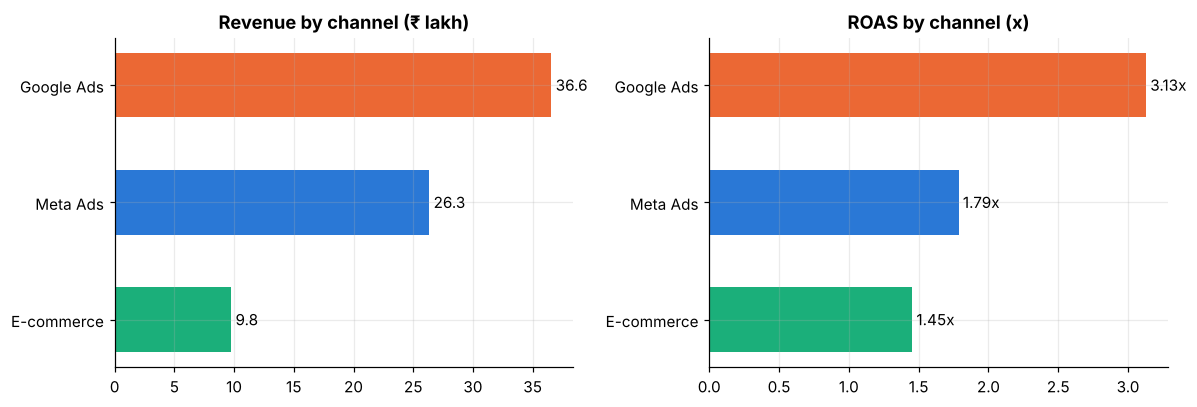

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
order = channel["Marketing_Channel"].tolist()
cols = [CH_COLORS[c] for c in order]
ax[0].barh(order, channel["Revenue"] / 1e5, color=cols, height=0.55)
ax[0].set_title("Revenue by channel (₹ lakh)"); ax[0].invert_yaxis()
for i, v in enumerate(channel["Revenue"] / 1e5):
    ax[0].text(v, i, f" {v:,.1f}", va="center")
ax[1].barh(order, channel["ROAS"], color=cols, height=0.55)
ax[1].set_title("ROAS by channel (x)"); ax[1].invert_yaxis()
for i, v in enumerate(channel["ROAS"]):
    ax[1].text(v, i, f" {v:.2f}x", va="center")
plt.tight_layout(); plt.savefig(CHARTS / "01_channel_revenue_roas.png", bbox_inches="tight"); plt.show()

### 4.2 Campaign-wise performance — top and underperforming campaigns

In [17]:
camp = summarise(df, ["Campaign_Name", "Marketing_Channel", "Campaign_Objective", "Product_Name",
                      "Audience_Type", "Ad_Creative_Type"]).sort_values("ROAS", ascending=False)
camp["Spend_Share_%"] = camp["Ad_Spend"] / tot.Ad_Spend * 100
camp["New_Cust_Share_%"] = camp["New_Customers"] / camp["Orders"] * 100
camp[["Campaign_Name", "Marketing_Channel", "Campaign_Objective", "Ad_Spend", "Revenue", "Orders",
      "New_Customers", "ROAS", "CAC", "CTR_%", "CPC", "CVR_%", "AOV", "New_Cust_Share_%"]]

,Campaign_Name,Marketing_Channel,Campaign_Objective,Ad_Spend,Revenue,Orders,New_Customers,ROAS,CAC,CTR_%,CPC,CVR_%,AOV,New_Cust_Share_%
4,GGL_Search_Brand,Google Ads,Conversions,"133,042.89","1,650,910.15",2651,777,12.41,171.23,8.68,4.44,8.85,622.75,29.31
12,META_Retargeting_Combo_Offer,Meta Ads,Conversions,"93,941.18","539,375.93",541,217,5.74,432.91,1.89,12.36,7.12,997.00,40.11
13,META_Retargeting_Shampoo_Carousel,Meta Ads,Conversions,"162,666.69","526,552.89",1016,446,3.24,364.72,2.09,10.08,6.29,518.26,43.90
5,GGL_Search_Generic_HairFall,Google Ads,Conversions,"347,777.20","1,096,071.88",1753,1466,3.15,237.23,4.16,7.17,3.61,625.25,83.63
0,ECOM_Amazon_SP_HairSerum,E-commerce,Sales,"274,170.97","588,801.79",982,647,2.15,423.76,0.83,26.59,9.52,599.59,65.89
10,META_Prospecting_HairSerum_UGC,Meta Ads,Conversions,"400,417.26","725,221.47",1158,874,1.81,458.14,1.34,10.96,3.17,626.27,75.47
6,GGL_Shopping_Sunscreen,Google Ads,Sales,"210,432.19","378,986.13",882,689,1.80,305.42,1.61,10.05,4.21,429.69,78.12
3,GGL_PMax_OnionHairOil,Google Ads,Sales,"289,567.08","436,413.55",915,608,1.51,476.26,1.12,10.90,3.44,476.95,66.45
2,ECOM_Nykaa_Sponsored_VitC,E-commerce,Sales,"220,946.54","310,348.84",580,378,1.40,584.51,0.75,26.69,7.01,535.08,65.17
11,META_Prospecting_VitC_Influencer,Meta Ads,Conversions,"328,977.71","412,704.99",758,582,1.25,565.25,1.28,11.89,2.74,544.47,76.78


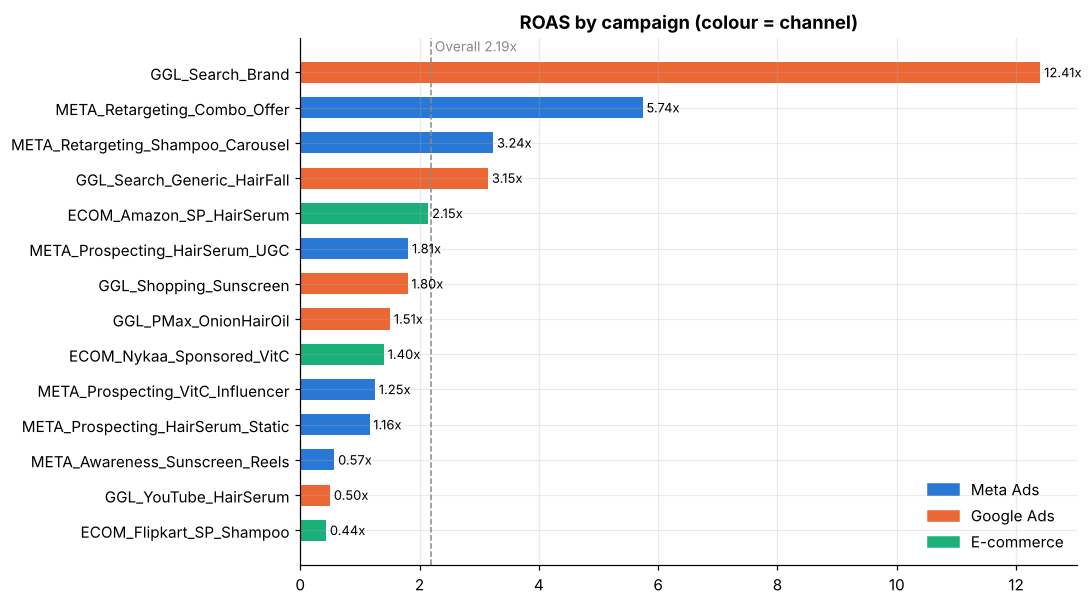

In [18]:
fig, ax = plt.subplots(figsize=(10, 5.6))
c2 = camp.sort_values("ROAS")
ax.barh(c2["Campaign_Name"], c2["ROAS"], color=[CH_COLORS[c] for c in c2["Marketing_Channel"]], height=0.6)
ax.axvline(overall.ROAS, color=GREY, ls="--", lw=1)
ax.text(overall.ROAS, len(c2) - 0.4, f" Overall {overall.ROAS:.2f}x", color=GREY, fontsize=9)
for i, v in enumerate(c2["ROAS"]):
    ax.text(v, i, f" {v:.2f}x", va="center", fontsize=8.5)
ax.set_title("ROAS by campaign (colour = channel)")
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in CH_COLORS.values()]
ax.legend(handles, CH_COLORS.keys(), loc="lower right", frameon=False)
plt.tight_layout(); plt.savefig(CHARTS / "02_campaign_roas.png", bbox_inches="tight"); plt.show()

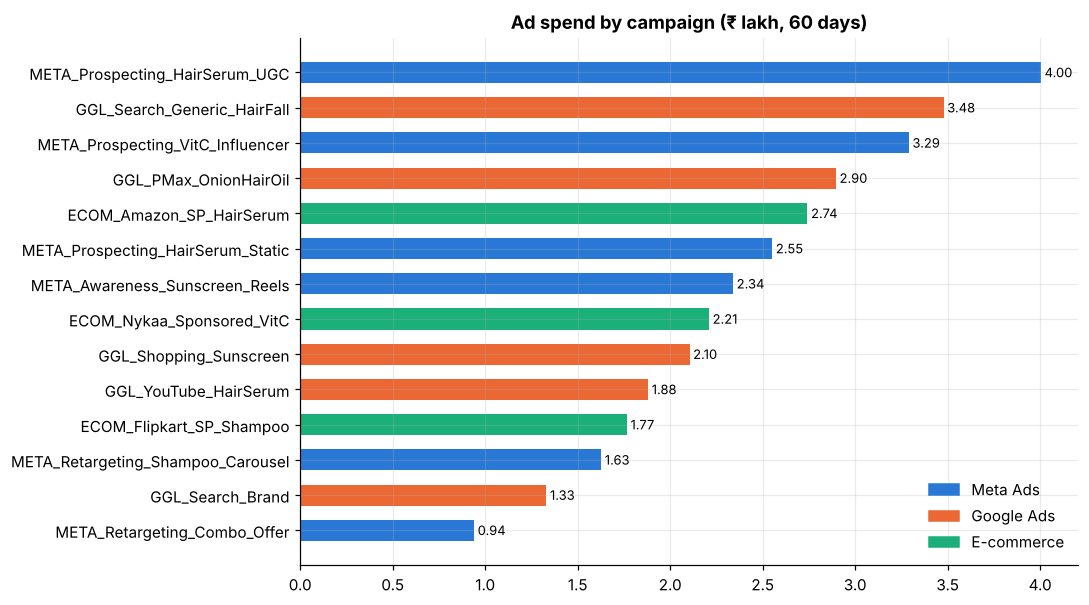

In [19]:
fig, ax = plt.subplots(figsize=(10, 5.6))
c3 = camp.sort_values("Ad_Spend")
ax.barh(c3["Campaign_Name"], c3["Ad_Spend"] / 1e5, color=[CH_COLORS[c] for c in c3["Marketing_Channel"]], height=0.6)
for i, v in enumerate(c3["Ad_Spend"] / 1e5):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=8.5)
ax.set_title("Ad spend by campaign (₹ lakh, 60 days)")
ax.legend(handles, CH_COLORS.keys(), loc="lower right", frameon=False)
plt.tight_layout(); plt.savefig(CHARTS / "03_campaign_spend.png", bbox_inches="tight"); plt.show()

### 4.3 Product-wise revenue

,Product_Name,Ad_Spend,Revenue,Revenue_Share_%,Orders,ROAS,CAC,CVR_%,AOV
1,Hair Growth Serum,"1,598,577.77","4,451,908.09",61.26,7174,2.78,373.85,4.59,620.56
5,Vitamin C Face Serum,"549,924.25","723,053.83",9.95,1338,1.31,572.84,3.72,540.40
3,Rice Water Shampoo,"339,244.12","603,485.70",8.30,1206,1.78,599.37,5.46,500.40
0,Hair Care Combo,"93,941.18","539,375.93",7.42,541,5.74,432.91,7.12,997.00
4,Sunscreen SPF 50,"444,398.71","513,186.70",7.06,1185,1.15,468.28,2.78,433.07
2,Onion Hair Oil,"289,567.08","436,413.55",6.01,915,1.51,476.26,3.44,476.95


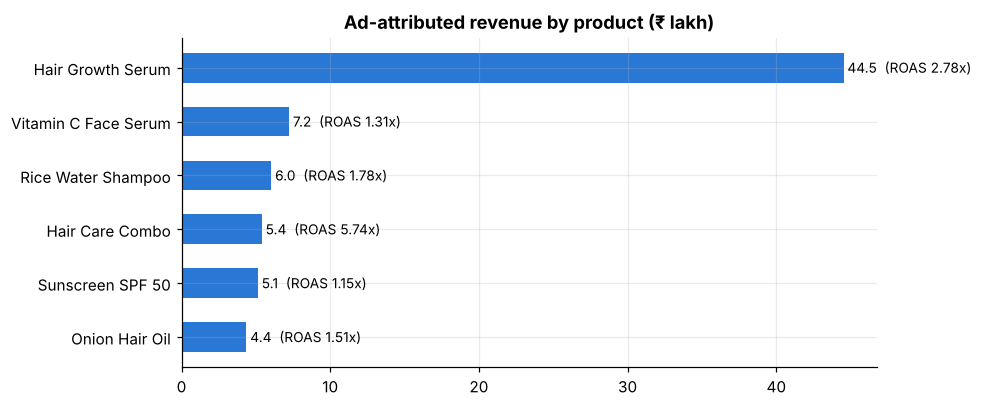

In [20]:
prod = summarise(df, "Product_Name").sort_values("Revenue", ascending=False)
prod["Revenue_Share_%"] = prod["Revenue"] / tot.Revenue * 100
display(prod[["Product_Name", "Ad_Spend", "Revenue", "Revenue_Share_%", "Orders", "ROAS", "CAC", "CVR_%", "AOV"]])

fig, ax = plt.subplots(figsize=(9, 3.8))
p2 = prod.sort_values("Revenue")
ax.barh(p2["Product_Name"], p2["Revenue"] / 1e5, color=BLUE, height=0.55)
for i, (v, r) in enumerate(zip(p2["Revenue"] / 1e5, p2["ROAS"])):
    ax.text(v, i, f" {v:,.1f}  (ROAS {r:.2f}x)", va="center", fontsize=9)
ax.set_title("Ad-attributed revenue by product (₹ lakh)")
plt.tight_layout(); plt.savefig(CHARTS / "04_product_revenue.png", bbox_inches="tight"); plt.show()

### 4.4 Daily and weekly trends

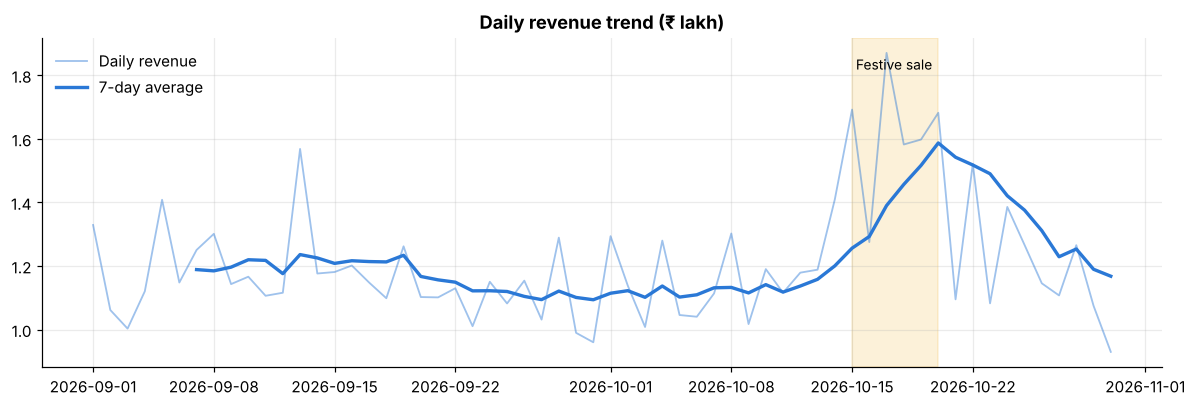

,Revenue_per_day,Spend_per_day,ROAS,CVR_%,CPM
Is_Festive_Sale,,,,,
No,"116,620.72","53,585.44",2.18,4.11,144.34
Yes,"161,650.79","70,339.90",2.30,5.37,167.43


In [21]:
daily = summarise(df, "Date")
weekly = summarise(df, "Week_Start")
daily["Revenue_7D_Avg"] = daily["Revenue"].rolling(7).mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily["Date"], daily["Revenue"] / 1e5, color=BLUE, lw=1.2, alpha=.45, label="Daily revenue")
ax.plot(daily["Date"], daily["Revenue_7D_Avg"] / 1e5, color=BLUE, lw=2.2, label="7-day average")
ax.axvspan(pd.Timestamp("2026-10-15"), pd.Timestamp("2026-10-20"), color="#eda100", alpha=.15)
ax.text(pd.Timestamp("2026-10-15"), ax.get_ylim()[1] * .97, " Festive sale", va="top", fontsize=9)
ax.set_title("Daily revenue trend (₹ lakh)"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(CHARTS / "05_daily_revenue.png", bbox_inches="tight"); plt.show()

fest_kpi = summarise(df, "Is_Festive_Sale").set_index("Is_Festive_Sale")
fest_days = df.groupby("Is_Festive_Sale")["Date"].nunique()
fest_view = pd.DataFrame({"Revenue_per_day": fest_kpi["Revenue"] / fest_days,
                          "Spend_per_day": fest_kpi["Ad_Spend"] / fest_days,
                          "ROAS": fest_kpi["ROAS"], "CVR_%": fest_kpi["CVR_%"], "CPM": fest_kpi["CPM"]})
fest_view

In [22]:
wk = summarise(df, "Is_Weekend").set_index("Is_Weekend")[["ROAS", "CVR_%", "CTR_%", "AOV"]]
print("Weekday vs weekend:"); display(wk)
weekly[["Week_Start", "Ad_Spend", "Revenue", "Orders", "ROAS", "CAC", "CVR_%"]]

Weekday vs weekend:


,ROAS,CVR_%,CTR_%,AOV
Is_Weekend,,,,
Weekday,2.16,4.14,1.30,589.63
Weekend,2.28,4.55,1.27,583.98


,Week_Start,Ad_Spend,Revenue,Orders,ROAS,CAC,CVR_%
0,2026-08-31,"318,900.23","706,907.68",1199,2.22,441.69,4.06
1,2026-09-07,"377,470.92","865,013.79",1441,2.29,437.90,4.23
2,2026-09-14,"382,951.53","816,844.63",1405,2.13,455.35,4.03
3,2026-09-21,"369,617.28","765,810.12",1310,2.07,450.20,4.02
4,2026-09-28,"380,196.39","795,744.76",1344,2.09,468.22,3.90
5,2026-10-05,"365,806.99","782,404.42",1317,2.14,439.67,4.07
6,2026-10-12,"441,662.04","1,019,553.86",1747,2.31,405.57,4.88
7,2026-10-19,"410,722.41","962,938.84",1654,2.34,411.55,4.86
8,2026-10-26,"268,325.32","552,205.70",942,2.06,447.96,4.01


### 4.5 Customer acquisition — new vs returning customers

,Marketing_Channel,New_Customers,Returning_Customers,CAC,New_Cust_Share_%
1,Google Ads,3672,2678,318.32,57.83
2,Meta Ads,2759,1498,534.65,64.81
0,E-commerce,1145,607,586.63,65.35


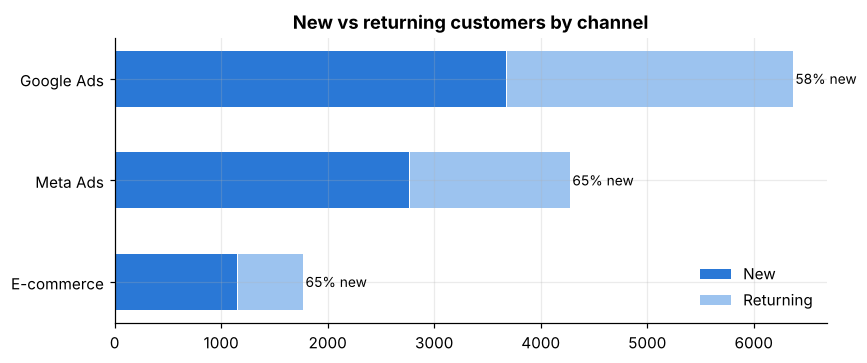

In [23]:
nr = channel[["Marketing_Channel", "New_Customers", "Returning_Customers", "CAC", "New_Cust_Share_%"]]
display(nr)
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(channel))
ax.barh(y, channel["New_Customers"], color=BLUE, height=.55, label="New")
ax.barh(y, channel["Returning_Customers"], left=channel["New_Customers"] + 15, color="#9cc3ef", height=.55, label="Returning")
ax.set_yticks(y, channel["Marketing_Channel"]); ax.invert_yaxis()
for i, (n_, r_) in enumerate(zip(channel["New_Customers"], channel["Returning_Customers"])):
    ax.text(n_ + r_ + 40, i, f"{n_/(n_+r_)*100:.0f}% new", va="center", fontsize=9)
ax.set_title("New vs returning customers by channel"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(CHARTS / "06_new_vs_returning.png", bbox_inches="tight"); plt.show()

### 4.6 Audience-wise and creative-wise performance

In [24]:
aud = summarise(df, "Audience_Type").sort_values("ROAS", ascending=False)
aud["New_Cust_Share_%"] = aud["New_Customers"] / aud["Orders"] * 100
aud[["Audience_Type", "Ad_Spend", "Revenue", "ROAS", "CAC", "CTR_%", "CVR_%", "New_Cust_Share_%"]]

,Audience_Type,Ad_Spend,Revenue,ROAS,CAC,CTR_%,CVR_%,New_Cust_Share_%
0,Brand Search,"133,042.89","1,650,910.15",12.41,171.23,8.68,8.85,29.31
9,Retargeting - Site Visitors,"93,941.18","539,375.93",5.74,432.91,1.89,7.12,40.11
8,Retargeting - Cart Abandoners,"162,666.69","526,552.89",3.24,364.72,2.09,6.29,43.90
3,Non-Brand Search,"347,777.20","1,096,071.88",3.15,237.23,4.16,3.61,83.63
10,Shopping - In-Market,"210,432.19","378,986.13",1.80,305.42,1.61,4.21,78.12
6,Prospecting - Interest,"729,394.97","1,137,926.46",1.56,500.96,1.31,2.98,75.99
4,Performance Max - Mixed,"289,567.08","436,413.55",1.51,476.26,1.12,3.44,66.45
2,Marketplace - Keyword,"450,748.40","665,734.60",1.48,587.68,0.76,7.22,65.44
1,Marketplace - Category,"220,946.54","310,348.84",1.40,584.51,0.75,7.01,65.17
7,Prospecting - Lookalike,"255,125.10","296,505.79",1.16,671.38,0.95,2.65,79.00


In [25]:
crea = summarise(df, "Ad_Creative_Type").sort_values("ROAS", ascending=False)
crea[["Ad_Creative_Type", "Ad_Spend", "Revenue", "ROAS", "CAC", "CTR_%", "CPC", "CVR_%"]]

,Ad_Creative_Type,Ad_Spend,Revenue,ROAS,CAC,CTR_%,CPC,CVR_%
8,Text Ad,"480,820.09","2,746,982.03",5.71,214.36,5.19,6.13,5.61
0,Carousel,"162,666.69","526,552.89",3.24,364.72,2.09,10.08,6.29
7,Static Image,"349,066.28","835,881.72",2.39,584.70,1.11,13.56,3.97
9,UGC Video,"400,417.26","725,221.47",1.81,458.14,1.34,10.96,3.17
4,Product Listing Ad,"210,432.19","378,986.13",1.80,305.42,1.61,10.05,4.21
1,Dynamic / Mixed,"289,567.08","436,413.55",1.51,476.26,1.12,10.90,3.44
6,Sponsored Product,"671,694.94","976,083.44",1.45,586.63,0.76,27.40,7.15
2,Influencer Video,"328,977.71","412,704.99",1.25,565.25,1.28,11.89,2.74
5,Short Video (Reels),"233,966.52","134,200.57",0.57,899.87,0.71,10.77,1.39
3,Long Video,"188,044.35","94,397.01",0.50,"1,424.58",0.41,14.74,1.17


In [26]:
# Fair creative comparison: same channel (Meta), same objective (Conversions), prospecting only
meta_pro = df[(df["Marketing_Channel"] == "Meta Ads") & (df["Audience_Type"].str.startswith("Prospecting"))
              & (df["Campaign_Objective"] == "Conversions")]
summarise(meta_pro, ["Ad_Creative_Type", "Campaign_Name"])[["Ad_Creative_Type", "Campaign_Name", "Ad_Spend", "ROAS", "CAC", "CTR_%", "CPC", "CVR_%"]]

,Ad_Creative_Type,Campaign_Name,Ad_Spend,ROAS,CAC,CTR_%,CPC,CVR_%
0,Influencer Video,META_Prospecting_VitC_Influencer,"328,977.71",1.25,565.25,1.28,11.89,2.74
1,Static Image,META_Prospecting_HairSerum_Static,"255,125.10",1.16,671.38,0.95,14.07,2.65
2,UGC Video,META_Prospecting_HairSerum_UGC,"400,417.26",1.81,458.14,1.34,10.96,3.17


### 4.7 Creative fatigue check
A creative "fatigues" when the same people see it too often and stop clicking. We look at weekly
CTR per Meta prospecting campaign: a steady decline is the warning sign.

Campaign_Name,META_Awareness_Sunscreen_Reels,META_Prospecting_HairSerum_Static,META_Prospecting_HairSerum_UGC,META_Prospecting_VitC_Influencer,META_Retargeting_Combo_Offer,META_Retargeting_Shampoo_Carousel
Week_Start,,,,,,
2026-08-31,0.70,0.93,1.38,1.56,1.87,2.09
2026-09-07,0.72,0.90,1.32,1.49,1.87,2.07
2026-09-14,0.72,0.94,1.31,1.43,1.93,2.29
2026-09-21,0.75,0.95,1.24,1.37,1.76,1.99
2026-09-28,0.74,1.00,1.36,1.32,1.88,2.16
2026-10-05,0.67,0.98,1.29,1.33,1.74,1.99
2026-10-12,0.70,0.93,1.44,1.05,1.97,2.00
2026-10-19,0.68,0.92,1.33,1.02,1.99,2.16
2026-10-26,0.66,0.96,1.40,0.95,2.09,2.06


,CTR_%_First4W,CTR_%_Last4W,CTR_Change_%,ROAS_First4W,ROAS_Last4W,ROAS_Change_%
Campaign_Name,,,,,,
META_Prospecting_VitC_Influencer,1.46,1.11,-23.67,1.43,1.11,-22.28
GGL_Search_Brand,8.95,8.37,-6.45,12.81,12.11,-5.44
META_Awareness_Sunscreen_Reels,0.72,0.68,-5.18,0.55,0.62,11.20
ECOM_Flipkart_SP_Shampoo,0.67,0.64,-3.96,0.43,0.46,5.67
META_Retargeting_Shampoo_Carousel,2.11,2.07,-1.89,3.30,3.24,-1.75
GGL_Shopping_Sunscreen,1.61,1.61,-0.21,1.76,1.83,4.12
ECOM_Nykaa_Sponsored_VitC,0.75,0.75,0.31,1.29,1.49,15.92
GGL_YouTube_HairSerum,0.41,0.41,0.45,0.51,0.52,1.86
GGL_Search_Generic_HairFall,4.14,4.18,0.97,3.18,3.21,1.17


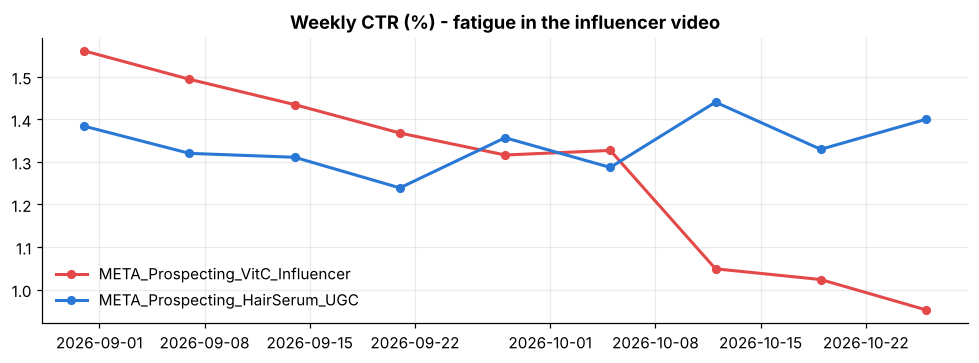

In [27]:
wc = summarise(df[df["Marketing_Channel"] == "Meta Ads"], ["Week_Start", "Campaign_Name"])
pivot_ctr = wc.pivot(index="Week_Start", columns="Campaign_Name", values="CTR_%")
display(pivot_ctr.round(2))

first4 = df["Date"] < "2026-09-29"; last4 = df["Date"] >= "2026-10-03"
trend = summarise(df[first4], "Campaign_Name").set_index("Campaign_Name")[["CTR_%", "ROAS", "CAC"]].join(
        summarise(df[last4], "Campaign_Name").set_index("Campaign_Name")[["CTR_%", "ROAS", "CAC"]], lsuffix="_First4W", rsuffix="_Last4W")
trend["CTR_Change_%"] = (trend["CTR_%_Last4W"] / trend["CTR_%_First4W"] - 1) * 100
trend["ROAS_Change_%"] = (trend["ROAS_Last4W"] / trend["ROAS_First4W"] - 1) * 100
display(trend.sort_values("CTR_Change_%")[["CTR_%_First4W", "CTR_%_Last4W", "CTR_Change_%", "ROAS_First4W", "ROAS_Last4W", "ROAS_Change_%"]])

fat = "META_Prospecting_VitC_Influencer"
fig, ax = plt.subplots(figsize=(9, 3.4))
for cname, colr in [(fat, "#e34948"), ("META_Prospecting_HairSerum_UGC", BLUE)]:
    s = pivot_ctr[cname]
    ax.plot(s.index, s.values, marker="o", ms=5, lw=2, color=colr, label=cname)
ax.set_title("Weekly CTR (%) - fatigue in the influencer video"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(CHARTS / "07_creative_fatigue.png", bbox_inches="tight"); plt.show()

### 4.8 Ad spend vs revenue
Does spending more on a given day bring more revenue? We check correlation **within** each campaign
(mixing campaigns would just show that big campaigns are big).

,Spend_Revenue_Corr
Campaign_Name,
GGL_Search_Brand,0.61
META_Prospecting_HairSerum_UGC,0.60
META_Retargeting_Shampoo_Carousel,0.52
ECOM_Amazon_SP_HairSerum,0.46
GGL_PMax_OnionHairOil,0.41
META_Prospecting_VitC_Influencer,0.40
ECOM_Nykaa_Sponsored_VitC,0.40
META_Retargeting_Combo_Offer,0.39
META_Awareness_Sunscreen_Reels,0.33


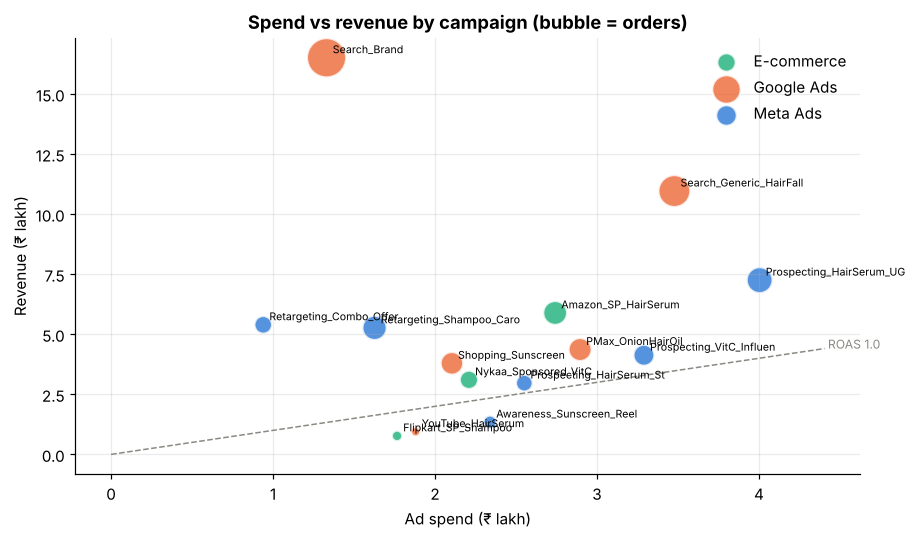

In [28]:
corr = df.groupby("Campaign_Name").apply(lambda g: g["Ad_Spend"].corr(g["Revenue"]), include_groups=False).rename("Spend_Revenue_Corr")
display(corr.sort_values(ascending=False).to_frame())

fig = px.scatter(camp, x="Ad_Spend", y="Revenue", size="Orders", color="Marketing_Channel",
                 color_discrete_map=CH_COLORS, hover_name="Campaign_Name",
                 hover_data={"ROAS": ":.2f", "CAC": ":,.0f"},
                 title="Campaign spend vs revenue (bubble = orders). Dashed line = break-even at ROAS 1.0")
mx = camp["Ad_Spend"].max() * 1.05
fig.add_shape(type="line", x0=0, y0=0, x1=mx, y1=mx, line=dict(dash="dash", color=GREY))
fig.update_layout(template="simple_white", height=480)
fig.show()

fig, ax = plt.subplots(figsize=(8.5, 5))
for ch, g in camp.groupby("Marketing_Channel"):
    ax.scatter(g["Ad_Spend"] / 1e5, g["Revenue"] / 1e5, s=g["Orders"] / 4, color=CH_COLORS[ch], alpha=.8,
               edgecolor="white", lw=1.5, label=ch)
for _, r in camp.iterrows():
    ax.annotate(r["Campaign_Name"].split("_", 1)[1][:24], (r["Ad_Spend"] / 1e5, r["Revenue"] / 1e5),
                fontsize=7, xytext=(4, 3), textcoords="offset points")
lim = camp["Ad_Spend"].max() / 1e5 * 1.1
ax.plot([0, lim], [0, lim], ls="--", color=GREY, lw=1); ax.text(lim, lim, " ROAS 1.0", color=GREY, fontsize=8)
ax.set_xlabel("Ad spend (₹ lakh)"); ax.set_ylabel("Revenue (₹ lakh)")
ax.set_title("Spend vs revenue by campaign (bubble = orders)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(CHARTS / "08_spend_vs_revenue.png", bbox_inches="tight"); plt.show()

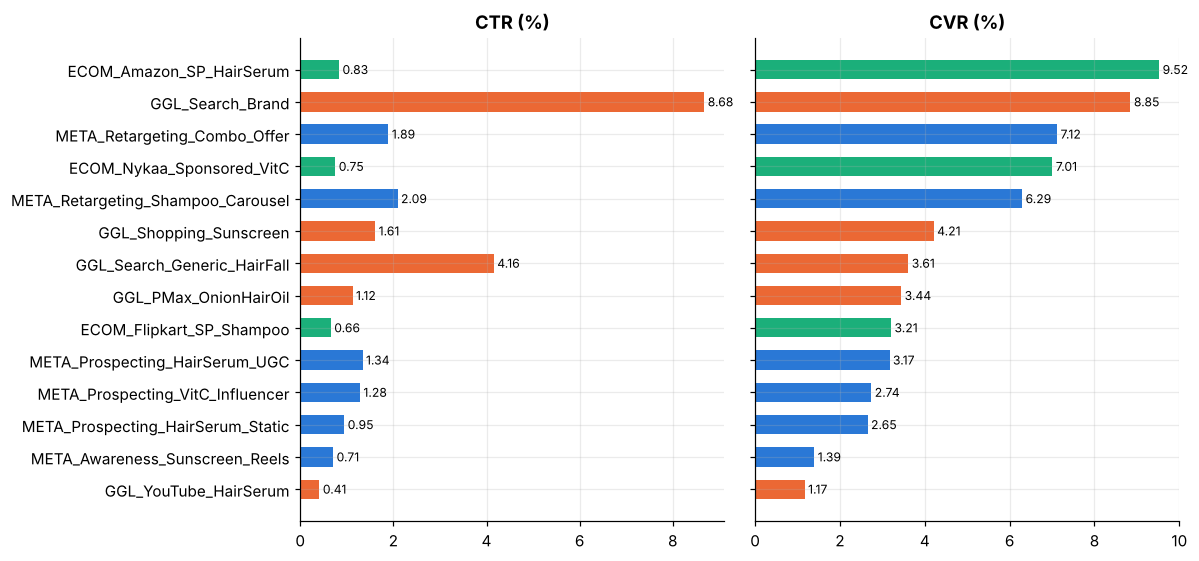

In [29]:
# Campaign conversion comparison (CTR and CVR side by side)
fig, ax = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
c4 = camp.sort_values("CVR_%")
colrs = [CH_COLORS[c] for c in c4["Marketing_Channel"]]
ax[0].barh(c4["Campaign_Name"], c4["CTR_%"], color=colrs, height=.6); ax[0].set_title("CTR (%)")
ax[1].barh(c4["Campaign_Name"], c4["CVR_%"], color=colrs, height=.6); ax[1].set_title("CVR (%)")
for a, colname in [(ax[0], "CTR_%"), (ax[1], "CVR_%")]:
    for i, v in enumerate(c4[colname]):
        a.text(v, i, f" {v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(CHARTS / "09_campaign_ctr_cvr.png", bbox_inches="tight"); plt.show()

## 5. Budget optimisation (not ROAS alone)

**Why not just move all money to the highest-ROAS campaign?**
* ROAS ignores **margin**: ₹1 of revenue on a marketplace keeps less money (commission + fees) than ₹1 on our own website.
* High-ROAS campaigns like **brand search** and **retargeting** mostly reach people who already know us —
  they have a small audience and low new-customer share, so extra budget adds little *new* business.
* Small campaigns can show lucky ROAS; we need **enough orders** to trust the number.
* **Awareness** campaigns are designed for reach, not immediate sales; judging them by ROAS alone is unfair,
  but their spend still needs a cap.

**Assumptions (clearly labelled, not observed data):**
| Assumption | Value | Why |
|---|---|---|
| Contribution margin before ads – own website (Meta/Google traffic) | 55% of revenue | after product cost, shipping, payment fees, returns |
| Contribution margin before ads – marketplaces | 40% of revenue | marketplace commission & fulfilment fees |
| Break-even ROAS | 1 ÷ margin = 1.82× website, 2.50× marketplace | below this, each sale loses money after ad cost |
| Target CAC | ₹450 | assumed affordable cost to acquire a customer who may re-order |
| Minimum volume to trust a campaign | 300 orders in 60 days | avoids decisions on noise |

In [30]:
MARGIN = {"Meta Ads": 0.55, "Google Ads": 0.55, "E-commerce": 0.40}
TARGET_CAC, MIN_ORDERS = 450, 300

b = camp.merge(trend[["CTR_Change_%", "ROAS_Change_%"]], left_on="Campaign_Name", right_index=True)
b["Margin"] = b["Marketing_Channel"].map(MARGIN)
b["Breakeven_ROAS"] = 1 / b["Margin"]
b["Profit_Index"] = b["ROAS"] / b["Breakeven_ROAS"]                     # >1 = profitable after ad cost
b["Contribution_After_Ads"] = b["Revenue"] * b["Margin"] - b["Ad_Spend"]
b["Channel_Median_CVR"] = b.groupby("Marketing_Channel")["CVR_%"].transform("median")

def decide(r):
    reasons = []
    if r.Campaign_Objective == "Awareness":
        return ("Cap & measure differently", -15,
                f"Awareness objective; ROAS {r.ROAS:.2f}x is below break-even {r.Breakeven_ROAS:.2f}x and CAC ₹{r.CAC:,.0f}. "
                "Keep a capped budget, judge on CPM/reach and brand-search lift, trim 15%.")
    if r.Audience_Type == "Brand Search" or r.Audience_Type.startswith("Retargeting"):
        return ("Maintain (limited headroom)", 0,
                f"High ROAS {r.ROAS:.2f}x but only {r['New_Cust_Share_%']:.0f}% new customers and a finite audience "
                "(people who already know the brand). Extra budget mostly buys sales that may happen anyway.")
    if r.Profit_Index >= 1.3 and r.CAC <= TARGET_CAC and r.Orders >= MIN_ORDERS and r["ROAS_Change_%"] > -10:
        return ("Scale test (+25%)", 25,
                f"Profitable (ROAS {r.ROAS:.2f}x vs break-even {r.Breakeven_ROAS:.2f}x), CAC ₹{r.CAC:,.0f} under ₹{TARGET_CAC} target, "
                f"{r.Orders:,.0f} orders, stable trend. Increase in steps and watch marginal CAC.")
    if r.Profit_Index < 1.0 and r.CAC > TARGET_CAC * 1.2:
        return ("Reduce (-30%) & fix", -30,
                f"Loses money after ad cost (ROAS {r.ROAS:.2f}x < break-even {r.Breakeven_ROAS:.2f}x) and CAC ₹{r.CAC:,.0f} is "
                f"{r.CAC/TARGET_CAC:.1f}x target. CVR {r['CVR_%']:.2f}% vs channel median {r.Channel_Median_CVR:.2f}%.")
    if r["CTR_Change_%"] < -20:
        reasons.append(f"CTR fell {abs(r['CTR_Change_%']):.0f}% (first 4 vs last 4 weeks) = creative fatigue; refresh creative")
    if r.CAC > TARGET_CAC:
        reasons.append(f"CAC ₹{r.CAC:,.0f} above ₹{TARGET_CAC} target")
    if r["CVR_%"] < r.Channel_Median_CVR:
        reasons.append(f"CVR {r['CVR_%']:.2f}% below channel median {r.Channel_Median_CVR:.2f}%")
    if r.Profit_Index < 1:
        reasons.append(f"ROAS {r.ROAS:.2f}x is {'just under' if r.Profit_Index >= 0.95 else 'below'} break-even {r.Breakeven_ROAS:.2f}x (profit index {r.Profit_Index:.2f})")
    if not reasons:
        reasons.append(f"Profitable (index {r.Profit_Index:.2f}) but not strong enough on every test to scale")
    return ("Optimise (hold budget)", 0, "; ".join(reasons) + ".")

b[["Decision", "Budget_Change_%", "Reason"]] = b.apply(lambda r: pd.Series(decide(r)), axis=1)
b["Current_Daily_Budget"] = b["Ad_Spend"] / 60
b["Proposed_Daily_Budget"] = b["Current_Daily_Budget"] * (1 + b["Budget_Change_%"] / 100)
budget = b.sort_values(["Budget_Change_%", "Profit_Index"], ascending=[False, False])
budget[["Campaign_Name", "ROAS", "Breakeven_ROAS", "Profit_Index", "CAC", "CVR_%", "Orders",
        "New_Cust_Share_%", "CTR_Change_%", "Decision", "Budget_Change_%"]]

,Campaign_Name,ROAS,Breakeven_ROAS,Profit_Index,CAC,CVR_%,Orders,New_Cust_Share_%,CTR_Change_%,Decision,Budget_Change_%
5,GGL_Search_Generic_HairFall,3.15,1.82,1.73,237.23,3.61,1753,83.63,0.97,Scale test (+25%),25
4,GGL_Search_Brand,12.41,1.82,6.82,171.23,8.85,2651,29.31,-6.45,Maintain (limited headroom),0
12,META_Retargeting_Combo_Offer,5.74,1.82,3.16,432.91,7.12,541,40.11,2.74,Maintain (limited headroom),0
13,META_Retargeting_Shampoo_Carousel,3.24,1.82,1.78,364.72,6.29,1016,43.90,-1.89,Maintain (limited headroom),0
10,META_Prospecting_HairSerum_UGC,1.81,1.82,1.00,458.14,3.17,1158,75.47,3.00,Optimise (hold budget),0
6,GGL_Shopping_Sunscreen,1.80,1.82,0.99,305.42,4.21,882,78.12,-0.21,Optimise (hold budget),0
0,ECOM_Amazon_SP_HairSerum,2.15,2.50,0.86,423.76,9.52,982,65.89,2.93,Optimise (hold budget),0
3,GGL_PMax_OnionHairOil,1.51,1.82,0.83,476.26,3.44,915,66.45,1.47,Optimise (hold budget),0
8,META_Awareness_Sunscreen_Reels,0.57,1.82,0.32,899.87,1.39,303,85.81,-5.18,Cap & measure differently,-15
7,GGL_YouTube_HairSerum,0.50,1.82,0.28,"1,424.58",1.17,149,88.59,0.45,Cap & measure differently,-15


In [31]:
for _, r in budget.iterrows():
    print(f"{r.Decision:<28} {r.Campaign_Name:<36} {r.Reason}")

Scale test (+25%)            GGL_Search_Generic_HairFall          Profitable (ROAS 3.15x vs break-even 1.82x), CAC ₹237 under ₹450 target, 1,753 orders, stable trend. Increase in steps and watch marginal CAC.
Maintain (limited headroom)  GGL_Search_Brand                     High ROAS 12.41x but only 29% new customers and a finite audience (people who already know the brand). Extra budget mostly buys sales that may happen anyway.
Maintain (limited headroom)  META_Retargeting_Combo_Offer         High ROAS 5.74x but only 40% new customers and a finite audience (people who already know the brand). Extra budget mostly buys sales that may happen anyway.
Maintain (limited headroom)  META_Retargeting_Shampoo_Carousel    High ROAS 3.24x but only 44% new customers and a finite audience (people who already know the brand). Extra budget mostly buys sales that may happen anyway.
Optimise (hold budget)       META_Prospecting_HairSerum_UGC       CAC ₹458 above ₹450 target; ROAS 1.81x is just under br

### 5.1 Budget-neutral reallocation scenario
Money freed from "Reduce" and "Cap" campaigns is redistributed so **total budget stays the same**:
* "Scale test" campaigns get at most **+25%** — scaling in steps lets us see if CAC rises as we spend more.
* The rest goes into a **creative-testing reserve** (new UGC videos for Vitamin C serum and Hair Serum
  prospecting). Its return is unknown until tested, so the scenario does **not** count any revenue from it.

**Scenario assumption:** extra money is less efficient than existing money (diminishing returns), so new spend
is assumed to earn **70% of the campaign's current ROAS**. Money removed is assumed to lose revenue at the
campaign's current ROAS. This is a *planning scenario*, not a forecast.

In [32]:
MAX_SCALE = 0.25
cut = b["Budget_Change_%"] < 0
freed = (b.loc[cut, "Current_Daily_Budget"] * -b.loc[cut, "Budget_Change_%"] / 100).sum()
scale = b["Budget_Change_%"] > 0
b.loc[scale, "Proposed_Daily_Budget"] = b.loc[scale, "Current_Daily_Budget"] * (1 + MAX_SCALE)
to_scale = (b.loc[scale, "Proposed_Daily_Budget"] - b.loc[scale, "Current_Daily_Budget"]).sum()
reserve = freed - to_scale
b["Budget_Change_%"] = (b["Proposed_Daily_Budget"] / b["Current_Daily_Budget"] - 1) * 100
b["Delta_Spend_Daily"] = b["Proposed_Daily_Budget"] - b["Current_Daily_Budget"]
b["Delta_Revenue_Daily"] = np.where(b["Delta_Spend_Daily"] > 0, b["Delta_Spend_Daily"] * b["ROAS"] * 0.70,
                                    b["Delta_Spend_Daily"] * b["ROAS"])
b["Delta_Contribution_Daily"] = b["Delta_Revenue_Daily"] * b["Margin"] - b["Delta_Spend_Daily"]
d_rev = b.Delta_Revenue_Daily.sum(); d_con = b.Delta_Contribution_Daily.sum()
print(f"Freed daily budget: {inr(freed)}  ->  scale tests {inr(to_scale)}  +  creative-testing reserve {inr(reserve)}")
print(f"Total daily budget before: {inr(b.Current_Daily_Budget.sum())}  after: {inr(b.Proposed_Daily_Budget.sum() + reserve)} (incl. reserve)")
print(f"Scenario per day, excluding the reserve: revenue {inr(d_rev)}, contribution after ads {inr(d_con)} "
      f"(about {inr(d_con*30)} per 30 days)")
print("Read this as: we give up some low-margin revenue, but stop losing money on it, and free budget to find the next winner.")
budget = b.sort_values("Budget_Change_%", ascending=False)
budget[["Campaign_Name", "Decision", "Current_Daily_Budget", "Proposed_Daily_Budget", "Budget_Change_%",
        "Delta_Revenue_Daily", "Delta_Contribution_Daily"]]

Freed daily budget: ₹5,963  ->  scale tests ₹1,449  +  creative-testing reserve ₹4,514
Total daily budget before: ₹55,261  after: ₹55,261 (incl. reserve)
Scenario per day, excluding the reserve: revenue ₹-2,857, contribution after ads ₹3,233 (about ₹96,995 per 30 days)
Read this as: we give up some low-margin revenue, but stop losing money on it, and free budget to find the next winner.


,Campaign_Name,Decision,Current_Daily_Budget,Proposed_Daily_Budget,Budget_Change_%,Delta_Revenue_Daily,Delta_Contribution_Daily
5,GGL_Search_Generic_HairFall,Scale test (+25%),"5,796.29","7,245.36",25.00,"3,196.88",309.21
4,GGL_Search_Brand,Maintain (limited headroom),"2,217.38","2,217.38",0.00,0.00,0.00
12,META_Retargeting_Combo_Offer,Maintain (limited headroom),"1,565.69","1,565.69",0.00,0.00,0.00
13,META_Retargeting_Shampoo_Carousel,Maintain (limited headroom),"2,711.11","2,711.11",0.00,0.00,0.00
0,ECOM_Amazon_SP_HairSerum,Optimise (hold budget),"4,569.52","4,569.52",0.00,0.00,0.00
10,META_Prospecting_HairSerum_UGC,Optimise (hold budget),"6,673.62","6,673.62",0.00,0.00,0.00
6,GGL_Shopping_Sunscreen,Optimise (hold budget),"3,507.20","3,507.20",0.00,0.00,0.00
3,GGL_PMax_OnionHairOil,Optimise (hold budget),"4,826.12","4,826.12",0.00,0.00,0.00
8,META_Awareness_Sunscreen_Reels,Cap & measure differently,"3,899.44","3,314.53",-15.00,-335.50,400.39
7,GGL_YouTube_HairSerum,Cap & measure differently,"3,134.07","2,663.96",-15.00,-235.99,340.31


## 6. A/B test analysis
**Set-up (simulated):** one Meta campaign for Hair Growth Serum, same audience, same budget split 50/50,
14 days. Only the creative differs: **A = static product image**, **B = UGC testimonial video**.

**How we decide a winner:** we ask "could this difference be luck?" using a **two-proportion z-test**.
The **p-value** is the probability of seeing a gap this big if the ads were truly identical.
Convention: p < 0.05 → the difference is *statistically significant*.

In [33]:
ab = pd.read_csv(RAW / "ab_test_raw.csv", parse_dates=["Date"])
assert ab.isna().sum().sum() == 0 and not ab.duplicated().any()
assert (ab["Clicks"] <= ab["Impressions"]).all() and (ab["Orders"] <= ab["Clicks"]).all()
ab_cols = ["Ad_Spend", "Impressions", "Clicks", "Orders", "Revenue"]
abs_ = ab.groupby(["Variation", "Variation_Description"], as_index=False)[ab_cols].sum()
abs_["CTR_%"] = safe_div(abs_["Clicks"], abs_["Impressions"]) * 100
abs_["CPC"] = safe_div(abs_["Ad_Spend"], abs_["Clicks"])
abs_["CVR_%"] = safe_div(abs_["Orders"], abs_["Clicks"]) * 100
abs_["ROAS"] = safe_div(abs_["Revenue"], abs_["Ad_Spend"])
abs_["AOV"] = safe_div(abs_["Revenue"], abs_["Orders"])
abs_

,Variation,Variation_Description,Ad_Spend,Impressions,Clicks,Orders,Revenue,CTR_%,CPC,CVR_%,ROAS,AOV
0,A,A - Static Product Image,"34,403.17",245296,2959,87,"56,488.97",1.21,11.63,2.94,1.64,649.30
1,B,B - UGC Testimonial Video,"35,732.71",239562,3349,97,"59,030.12",1.40,10.67,2.90,1.65,608.56


In [34]:
def two_prop_z(x1, n1, x2, n2):
    """Two-proportion z-test. Returns (lift of 2 over 1 in %, z, two-sided p-value)."""
    p1, p2 = x1 / n1, x2 / n2
    p = (x1 + x2) / (n1 + n2)
    se = np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / se
    return (p2 / p1 - 1) * 100, z, 2 * (1 - stats.norm.cdf(abs(z)))

A, B = abs_.iloc[0], abs_.iloc[1]
ctr_lift, ctr_z, ctr_p = two_prop_z(A.Clicks, A.Impressions, B.Clicks, B.Impressions)
cvr_lift, cvr_z, cvr_p = two_prop_z(A.Orders, A.Clicks, B.Orders, B.Clicks)
# Orders per impression combines both steps (click AND buy)
opi_lift, opi_z, opi_p = two_prop_z(A.Orders, A.Impressions, B.Orders, B.Impressions)

# ROAS: compare daily ROAS with Welch's t-test + bootstrap CI (we only have daily totals for revenue)
dA = ab[ab.Variation == "A"].set_index("Date"); dB = ab[ab.Variation == "B"].set_index("Date")
roas_A, roas_B = dA.Revenue / dA.Ad_Spend, dB.Revenue / dB.Ad_Spend
t_roas = stats.ttest_ind(roas_B, roas_A, equal_var=False)
rng = np.random.default_rng(0)
boot = []
for _ in range(5000):
    i = rng.integers(0, len(dA), len(dA)); j = rng.integers(0, len(dB), len(dB))
    boot.append(dB.Revenue.iloc[j].sum() / dB.Ad_Spend.iloc[j].sum() - dA.Revenue.iloc[i].sum() / dA.Ad_Spend.iloc[i].sum())
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])

ab_tests = pd.DataFrame([
    ["CTR (clicks / impressions)", A["CTR_%"], B["CTR_%"], ctr_lift, ctr_z, ctr_p],
    ["CVR (orders / clicks)", A["CVR_%"], B["CVR_%"], cvr_lift, cvr_z, cvr_p],
    ["Orders per 1,000 impressions", A.Orders / A.Impressions * 1000, B.Orders / B.Impressions * 1000, opi_lift, opi_z, opi_p],
    ["ROAS (daily, Welch t-test)", A.ROAS, B.ROAS, (B.ROAS / A.ROAS - 1) * 100, t_roas.statistic, t_roas.pvalue],
], columns=["Metric", "A", "B", "Lift_B_vs_A_%", "Test_Statistic", "p_value"])
ab_tests["Significant_at_95%"] = np.where(ab_tests["p_value"] < 0.05, "Yes", "No")
print(f"Bootstrap 95% CI for ROAS difference (B - A): {ci_lo:+.2f} to {ci_hi:+.2f}")
ab_tests

Bootstrap 95% CI for ROAS difference (B - A): -0.48 to +0.49


,Metric,A,B,Lift_B_vs_A_%,Test_Statistic,p_value,Significant_at_95%
0,CTR (clicks / impressions),1.21,1.40,15.89,5.89,0.00,Yes
1,CVR (orders / clicks),2.94,2.90,-1.49,-0.10,0.92,No
2,"Orders per 1,000 impressions",0.35,0.40,14.16,0.90,0.37,No
3,"ROAS (daily, Welch t-test)",1.64,1.65,0.61,0.05,0.96,No


In [35]:
# How much data would we need to confirm the CVR difference? (80% power, 5% significance)
def n_per_group(p1, p2, alpha=0.05, power=0.80):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    pbar = (p1 + p2) / 2
    return ((za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2) / (p2 - p1) ** 2

pA, pB = A.Orders / A.Clicks, B.Orders / B.Clicks
need_clicks = n_per_group(pA, pB) if abs(pB - pA) > 1e-9 else np.inf
clicks_per_day = (A.Clicks + B.Clicks) / 2 / 14
print(f"Clicks per variation needed to detect the observed CVR gap ({pA*100:.2f}% vs {pB*100:.2f}%): {need_clicks:,.0f}")
print(f"Clicks per variation collected: {A.Clicks:,.0f} -> about {need_clicks/clicks_per_day:,.0f} days at current volume")
need_ctr = n_per_group(A.Clicks / A.Impressions, B.Clicks / B.Impressions)
print(f"Impressions per variation needed for the CTR gap: {need_ctr:,.0f} (collected {A.Impressions:,.0f})")
# Minimum detectable effect: smallest relative CVR lift this test could reliably detect
za, zb = stats.norm.ppf(0.975), stats.norm.ppf(0.80)
mde_abs = (za + zb) * np.sqrt(2 * pA * (1 - pA) / A.Clicks)
mde_rel = mde_abs / pA * 100
print(f"With {A.Clicks:,.0f} clicks per variation, this test could only detect a CVR change of about ±{mde_rel:.0f}% "
      f"({pA*100:.2f}% -> {(pA+mde_abs)*100:.2f}%). The observed gap ({cvr_lift:+.1f}%) is far smaller, i.e. practically no difference.")

Clicks per variation needed to detect the observed CVR gap (2.94% vs 2.90%): 2,318,693
Clicks per variation collected: 2,959 -> about 10,292 days at current volume
Impressions per variation needed for the CTR gap: 54,914 (collected 245,296)
With 2,959 clicks per variation, this test could only detect a CVR change of about ±42% (2.94% -> 4.17%). The observed gap (-1.5%) is far smaller, i.e. practically no difference.


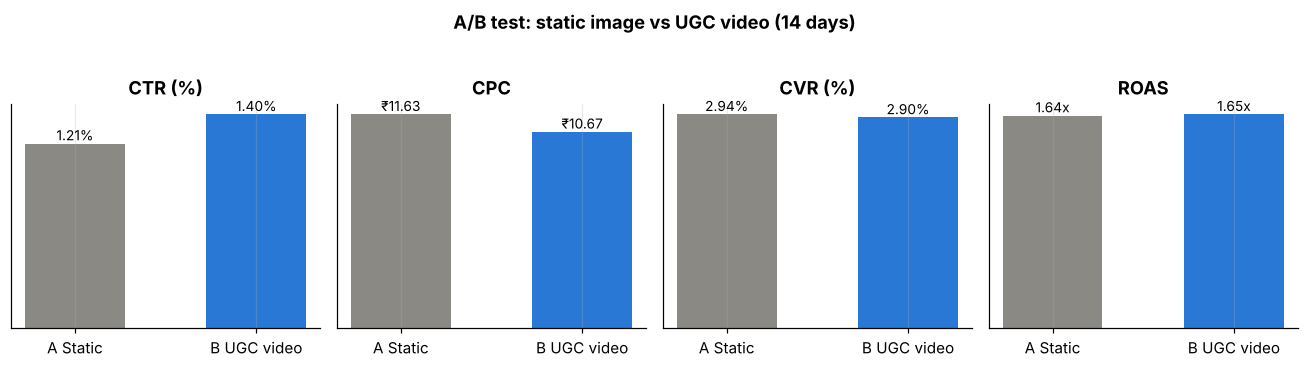

In [36]:
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
for a, (m, fmt) in zip(ax, [("CTR_%", "{:.2f}%"), ("CPC", "₹{:.2f}"), ("CVR_%", "{:.2f}%"), ("ROAS", "{:.2f}x")]):
    vals = abs_[m].values
    a.bar(["A Static", "B UGC video"], vals, color=[GREY, BLUE], width=.55)
    for i, v in enumerate(vals):
        a.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
    a.set_title(m.replace("_%", " (%)")); a.set_yticks([])
plt.suptitle("A/B test: static image vs UGC video (14 days)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.savefig(CHARTS / "10_ab_test.png", bbox_inches="tight"); plt.show()

## 7. Save outputs for Excel, SQL, Power BI and the report

In [37]:
out = df.copy()
out["Date"] = out["Date"].dt.strftime("%Y-%m-%d"); out["Week_Start"] = out["Week_Start"].dt.strftime("%Y-%m-%d")
base_cols = ["Row_ID", "Date", "Week_Start", "Day_Name", "Is_Weekend", "Is_Festive_Sale", "Marketing_Channel",
             "Campaign_Name", "Campaign_Objective", "Product_Name", "Audience_Type", "Ad_Creative_Type",
             "Ad_Spend", "Impressions", "Reach", "Clicks", "Orders", "New_Customers", "Returning_Customers",
             "Revenue", "Data_Quality_Flag"]
out[base_cols].to_csv(CLEAN / "campaign_performance_cleaned.csv", index=False)
out[base_cols + ["ROAS", "CAC", "CTR_%", "CPC", "CPM", "CVR_%", "AOV"]].round(4).to_csv(CLEAN / "campaign_performance_cleaned_with_kpis.csv", index=False)
ab_out = ab.copy(); ab_out["Date"] = ab_out["Date"].dt.strftime("%Y-%m-%d")
ab_out.to_csv(CLEAN / "ab_test_cleaned.csv", index=False)
cleaning_log.to_csv(CLEAN / "data_cleaning_log.csv", index=False)
camp.round(4).to_csv(CLEAN / "summary_campaign_kpis.csv", index=False)
channel.round(4).to_csv(CLEAN / "summary_channel_kpis.csv", index=False)
prod.round(4).to_csv(CLEAN / "summary_product_kpis.csv", index=False)
d_out = daily.copy(); d_out["Date"] = d_out["Date"].dt.strftime("%Y-%m-%d"); d_out.round(4).to_csv(CLEAN / "summary_daily_kpis.csv", index=False)
budget.round(4).to_csv(CLEAN / "budget_recommendations.csv", index=False)
abs_.round(4).to_csv(CLEAN / "ab_test_summary.csv", index=False)
ab_tests.round(6).to_csv(CLEAN / "ab_test_significance.csv", index=False)

results = {
    "overall": {k: float(v) for k, v in overall.items()},
    "fest": fest_view.round(4).to_dict(), "weekend": wk.round(4).to_dict(),
    "ab": {"ctr_lift": ctr_lift, "ctr_p": ctr_p, "cvr_lift": cvr_lift, "cvr_p": cvr_p, "opi_lift": opi_lift,
           "opi_p": opi_p, "roas_p": float(t_roas.pvalue), "roas_ci": [ci_lo, ci_hi], "need_clicks": need_clicks,
           "days_needed": need_clicks / clicks_per_day, "need_imp_ctr": need_ctr, "mde_rel": mde_rel},
    "realloc": {"freed_daily": freed, "to_scale_daily": to_scale, "reserve_daily": reserve,
                "delta_rev_daily": d_rev, "delta_contrib_daily": d_con},
    "corr": corr.round(3).to_dict(),
}
(ROOT / "data/cleaned/results.json").write_text(json.dumps(results, indent=2, default=float))
print("Saved:", sorted(p.name for p in CLEAN.iterdir()))

Saved: ['ab_test_cleaned.csv', 'ab_test_significance.csv', 'ab_test_summary.csv', 'budget_recommendations.csv', 'campaign_performance_cleaned.csv', 'campaign_performance_cleaned_with_kpis.csv', 'data_cleaning_log.csv', 'results.json', 'summary_campaign_kpis.csv', 'summary_channel_kpis.csv', 'summary_daily_kpis.csv', 'summary_product_kpis.csv']
